# Trabajo Práctico Especial: Staged Kidney Disease (CKD-NHANES 2021-2023)

## Carga de datos

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

data = pd.read_csv("CKD-NHANES/CKD_NHANES_2021_2023.csv", sep = ",", encoding = "latin1", on_bad_lines= "skip")
pd.set_option("display.max_columns", None)
data.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## Exploración inicial

### Tipos de datos y valores nulos

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

In [4]:
data.isna().sum()

participant_id                  0
age                             0
gender                          0
ethnicity                       0
education_level              4139
poverty_income_ratio         2041
bmi                          3462
weight_kg                    3179
height_cm                    3434
bp_systolic                  4416
bp_diastolic                 4416
serum_creatinine             5607
blood_urea_nitrogen          5607
albumin_serum                5567
phosphorus                   5611
bicarbonate                  5608
calcium                      5571
uric_acid                    5604
urine_creatinine             3779
urine_albumin                3780
albumin_creatinine_ratio     3780
diabetes_diagnosed            193
insulin_use                 10852
diabetes_pills               9652
ever_smoked                  3798
current_smoker               8690
egfr                         5607
ckd_stage                       0
ckd_present                     0
dtype: int64

### Frecuencia de valores por columna

In [5]:
cols = ["participant_id", "age", "gender", "ethnicity","education_level", "poverty_income_ratio", "bmi", "weight_kg", "height_cm", "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen", "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid", "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "diabetes_diagnosed", "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "egfr", "ckd_stage", "ckd_present"]
for c in cols:
    print(data[c].value_counts())
    print()

participant_id
130378.0    1
130379.0    1
130380.0    1
130381.0    1
130382.0    1
           ..
142306.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 11933, dtype: int64

age
80.0    525
8.0     257
5.0     246
4.0     229
12.0    228
       ... 
79.0     82
23.0     82
47.0     76
78.0     73
20.0     71
Name: count, Length: 81, dtype: int64

gender
Female    6358
Male      5575
Name: count, dtype: int64

ethnicity
Non-Hispanic White    6217
Non-Hispanic Black    1597
Other Hispanic        1373
Mexican American      1117
Other/Multiracial      948
Non-Hispanic Asian     681
Name: count, dtype: int64

education_level
5.0    2625
4.0    2370
3.0    1749
2.0     666
1.0     373
9.0      11
Name: count, dtype: int64

poverty_income_ratio
5.000000e+00    2149
5.397605e-79     100
1.850000e+00      74
2.160000e+00      64
1.370000e+00      58
                ... 
4.700000e+00       1
1.630000e+00       1
2.140000e+00       1
4.280000e+00       1
4.870

## Limpieza de datos

### Conversión de columnas a enteros

Estas columnas se guardan como decimales en el archivo, pero sus valores son enteros: códigos de categorías (educación, diabetes, tabaquismo), identificadores, edad o mediciones sin decimales. Se redondean y se pasan a `Int64`, el tipo entero de pandas que admite valores nulos.

In [6]:
columnas_enteras = ["participant_id", "age", "education_level", "bp_systolic", "bp_diastolic",
                    "blood_urea_nitrogen", "bicarbonate", "urine_creatinine", "diabetes_diagnosed",
                    "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "ckd_present"]

data[columnas_enteras] = data[columnas_enteras].round().astype("Int64")

### Códigos de falta de respuesta (7 y 9)

Según la metadata, en las variables de cuestionario el **7** significa "se negó a responder" y el **9** "no sabe". No son categorías reales, así que se reemplazan por valores nulos (`NaN`) para que no se cuenten como respuestas.

In [7]:
columnas_cuestionario = ["education_level", "diabetes_diagnosed", "diabetes_pills", "ever_smoked", "current_smoker"]

for columna in columnas_cuestionario:
    data[columna] = data[columna].replace([7, 9], np.nan)

data[columnas_cuestionario].isna().sum()

education_level       4150
diabetes_diagnosed     197
diabetes_pills        9659
ever_smoked           3812
current_smoker        8690
dtype: int64

### Verificación: diabetes vs medicación

Se revisa si hay personas sin diabetes diagnosticada (`diabetes_diagnosed == 2`) que usan insulina o pastillas para la diabetes.

In [8]:
sin_diabetes = data["diabetes_diagnosed"] == 2
con_insulina = data["insulin_use"] == 1
con_pastillas = data["diabetes_pills"] == 1

print(f"Sin diabetes y con insulina: {(sin_diabetes & con_insulina).sum()}")
print(f"Sin diabetes y con pastillas: {(sin_diabetes & con_pastillas).sum()}")
print(f"Sin diabetes y con insulina o pastillas: {(sin_diabetes & (con_insulina | con_pastillas)).sum()}")

Sin diabetes y con insulina: 0
Sin diabetes y con pastillas: 60
Sin diabetes y con insulina o pastillas: 60


Nadie sin diagnóstico usa insulina. Hay 60 personas sin diagnóstico que toman pastillas, pero estas pastillas no indican necesariamente que la persona tenga diabetes: también se recetan, por ejemplo, en casos de prediabetes. Por eso esos registros no se modifican.

### Verificación de valores fuera de rango

Se cuentan los registros con valores imposibles o muy poco plausibles para una persona en cada medición: edades negativas o mayores a 80 (el archivo agrupa en 80 a quienes tienen 80 años o más) y valores extremos en medidas corporales, presión arterial, análisis de sangre, orina y eGFR.

In [9]:
print((data["age"] < 0).sum())
print((data["age"] > 80).sum())

# Medidas corporales y presión arterial
print((data["bmi"] <= 0).sum())
print((data["bp_systolic"] <= 0).sum())
print((data["bp_systolic"] >= 300).sum())
print((data["bp_diastolic"] <= 0).sum())
print((data["bp_diastolic"] >= 360).sum())

# Análisis de sangre
print((data["serum_creatinine"] <= 0).sum())
print((data["serum_creatinine"] >= 53).sum())
print((data["blood_urea_nitrogen"] <= 0).sum())
print((data["albumin_serum"] <= 1.0).sum())
print((data["albumin_serum"] >= 8.1).sum())
print((data["phosphorus"] <= 0.3).sum())
print((data["phosphorus"] >= 12.0).sum())
print((data["bicarbonate"] <= 3).sum())
print((data["bicarbonate"] >= 60).sum())
print((data["calcium"] <= 6.0).sum())
print((data["calcium"] >= 17.0).sum())
print((data["uric_acid"] <= 1.0).sum())
print((data["uric_acid"] >= 20.0).sum())

# Análisis de orina
print((data["urine_creatinine"] <= 2).sum())
print((data["urine_albumin"] <= 0).sum())
print((data["urine_albumin"] >= 10000).sum())
print((data["albumin_creatinine_ratio"] <= 0).sum())

# Variable derivada
print((data["egfr"] <= 0).sum())

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


Ninguna variable tiene valores fuera de rango, por lo que no se elimina ni modifica ningún registro por este motivo.

### Etapa de CKD desconocida (`Unknown`)

Según la metadata, `ckd_stage` vale `Unknown` cuando no se pudo asignar una etapa (faltan los análisis necesarios), pero en `ckd_present` esos casos quedan codificados como **1**, igual que los enfermos. Si se dejaran así, se contarían como casos de CKD personas a las que no se les pudo evaluar la función renal. Por eso se reemplaza `Unknown` por un valor nulo en `ckd_stage` y también se deja nulo `ckd_present` en esas filas.

In [10]:
data.loc[data["ckd_stage"].isna(), "ckd_present"] = np.nan

print(f"Registros con etapa desconocida: {data['ckd_stage'].isna().sum()}")
print(data["ckd_stage"].value_counts())
print(data["ckd_present"].value_counts())

Registros con etapa desconocida: 0
ckd_stage
Unknown                         5607
No CKD                          3592
Stage 2 (Mildly Decreased)      1875
Stage 1 (Kidney Damage)          382
Stage 3a (Mild-Moderate)         341
Stage 3b (Moderate-Severe)        97
Stage 4 (Severely Decreased)      28
Stage 5 (Kidney Failure)          11
Name: count, dtype: int64
ckd_present
1    8341
0    3592
Name: count, dtype: Int64


### Registros duplicados

Se verifica que no haya filas repetidas ni participantes con el mismo identificador.

In [10]:
print(f"Filas duplicadas: {data.duplicated().sum()}")
print(f"participant_id duplicados: {data['participant_id'].duplicated().sum()}")

Filas duplicadas: 0
participant_id duplicados: 0


## Análisis de la hipótesis univariada

### Planteo de la hipótesis

**Hipótesis:** el porcentaje de fumadores actuales de cigarrillo entre los adultos del dataset (NHANES 2021-2023) **supera** el porcentaje de fumadores adultos de EE.UU. informado por el CDC.

**Valor de referencia:** según el CDC (Centros para el Control y la Prevención de Enfermedades), el **11,5 %** de los adultos (≥ 18 años) de EE.UU. fumaba cigarrillos en 2021.

Planteo de las hipótesis:
- **H0:** p = 0.115 (el porcentaje de fumadores del dataset es igual al de EE.UU.)
- **H1:** p > 0.115 (el porcentaje de fumadores del dataset supera al de EE.UU.)
- **Nivel de significancia:** α = 0.05

### Población observada

Se toman los adultos que respondieron válidamente `ever_smoked` (1 o 2). La pregunta solo se hizo a mayores de 18 años.

Se crea la variable `fumador`, que vale **1** si la persona fuma actualmente y **0** si no. El promedio de esta variable es la proporción de fumadores.

In [11]:
alpha = 0.05
p0 = 0.115

poblacion_observada = data[data["ever_smoked"].isin([1, 2])]
n_total_observados = len(poblacion_observada)

fumador = poblacion_observada["current_smoker"].isin([1, 2]).astype(int)
total_fumadores_activos = fumador.sum()
no_fumadores_total = n_total_observados - total_fumadores_activos

proporcion_de_fumadores = fumador.mean()
porcentaje_de_fumadores = proporcion_de_fumadores * 100

print(f"Edad mínima de la población observada: {poblacion_observada['age'].min():.0f} años")
print(f"Total de población adulta observada: {n_total_observados}")
print(f"Total de fumadores activos: {total_fumadores_activos}")
print(f"Total de personas que no fuman actualmente: {no_fumadores_total}")
print(f"Porcentaje de fumadores activos: {porcentaje_de_fumadores:.2f}%")
print(f"Porcentaje de referencia (CDC, EE.UU.): {p0 * 100:.1f}%")

Edad mínima de la población observada: 18 años
Total de población adulta observada: 8121
Total de fumadores activos: 1190
Total de personas que no fuman actualmente: 6931
Porcentaje de fumadores activos: 14.65%
Porcentaje de referencia (CDC, EE.UU.): 11.5%


### Test t para una muestra

Se usa el **test t para una muestra**, que compara la media de una variable contra un valor fijo. Como `fumador` vale 0 o 1, su media es la proporción de fumadores.

**Supuestos:**
- **Independencia:** cada fila es una persona distinta.
- **Normalidad:** una variable 0/1 no es normal, así que no tiene sentido aplicarle Shapiro-Wilk. El test igual es válido porque lo que se compara es la **media**, y con una muestra grande (n = 8121, muy por encima de 30) la media se distribuye aproximadamente normal (teorema central del límite).
- **Homocedasticidad:** no corresponde, porque hay un solo grupo y no hay varianzas que comparar.

Se usa `alternative="greater"` porque H1 dice que la proporción es **mayor** a 0.115 (test unilateral).

In [12]:
resultado = stats.ttest_1samp(fumador, popmean=p0, alternative="greater")

t_estadistico = resultado.statistic
p_valor = resultado.pvalue
grados_libertad = resultado.df
limite_inferior = resultado.confidence_interval(confidence_level=0.95).low

print(f"Estadístico t: {t_estadistico:.4f}")
print(f"Valor p: {p_valor:.4e}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Límite inferior del IC 95% (unilateral): {limite_inferior * 100:.2f}%")

if p_valor < alpha:
    print("Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.")
else:
    print("NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente para afirmar que es mayor al 11,5%.")

Estadístico t: 8.0351
Valor p: 5.3331e-16
Grados de libertad: 8120
Límite inferior del IC 95% (unilateral): 14.01%
Se RECHAZA la hipótesis nula (H0). El porcentaje de fumadores activos es significativamente mayor al 11,5%.


#### Qué representa cada valor que devuelve el test

- **Estadístico t:** cuántos errores estándar está la proporción del dataset por encima (+) o por debajo (−) del 11,5 %. Se calcula como (proporción observada − 0.115) / (desvío / √n). Un valor cercano a 0 indica que el dato es parecido a la referencia. Un valor grande y positivo indica que el dato está bien por encima.
- **Valor p:** la probabilidad de obtener una proporción tan alta como la observada (o más alta) **si H0 fuera cierta**, es decir, si en realidad fumara el 11,5 %. Si es menor a α = 0.05, el resultado es muy difícil de explicar por azar y se rechaza H0.
- **Grados de libertad (n − 1):** definen qué distribución t se usa para calcular el p-valor. Con n tan grande, la distribución t es prácticamente igual a una normal.
- **Límite inferior del IC 95 %:** como el test es unilateral ("mayor que"), el intervalo es de la forma [límite inferior, ∞). Se lee así: con un 95 % de confianza, el porcentaje real de fumadores de la población es **al menos** ese valor. Si ese límite queda por encima de 11,5 %, la conclusión coincide con la del p-valor.

### Gráfico: proporción del dataset

Usamos un **gráfico de barras**, que sirve para comparar valores entre categorías:
- **Barra azul:** porcentaje de fumadores del dataset, con su intervalo de confianza del 95 % como barra de error (la "rayita" negra).
- **Barra gris:** porcentaje de referencia del CDC.
- **Línea roja punteada:** el valor de H0 (11,5 %).

**Cómo se interpreta:** si toda la barra de error de la barra azul queda por encima de la línea roja, la diferencia no se explica por el azar del muestreo. Eso coincide con rechazar H0. Si la barra de error tocara o cruzara la línea, no habría evidencia suficiente.

Para la barra de error se usa el intervalo de confianza **bilateral** del 95 % (proporción ± margen), que es el que se grafica habitualmente.

IC 95% bilateral: [13.88%, 15.42%]


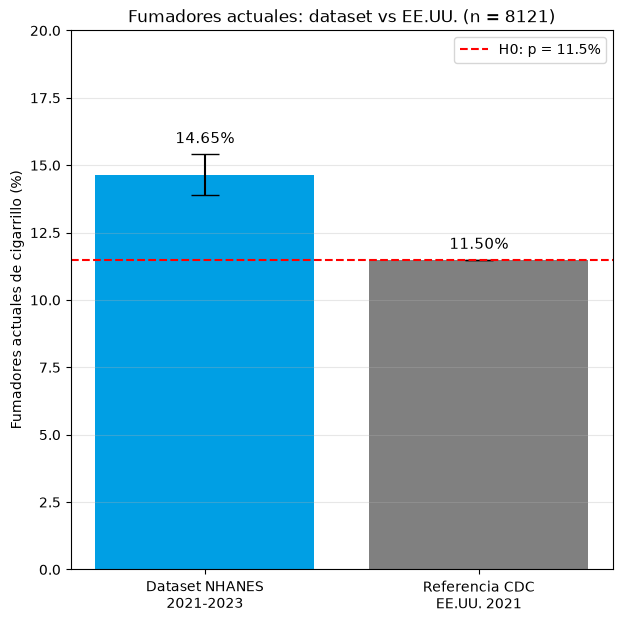

In [13]:
ic_bilateral = stats.ttest_1samp(fumador, popmean=p0).confidence_interval(confidence_level=0.95)
error_inferior = (proporcion_de_fumadores - ic_bilateral.low) * 100
error_superior = (ic_bilateral.high - proporcion_de_fumadores) * 100

print(f"IC 95% bilateral: [{ic_bilateral.low * 100:.2f}%, {ic_bilateral.high * 100:.2f}%]")

categorias = ["Dataset NHANES\n2021-2023", "Referencia CDC\nEE.UU. 2021"]
valores = [porcentaje_de_fumadores, p0 * 100]

plt.figure(figsize=(7, 7))
plt.bar(categorias, valores, color=["#009FE4", "gray"],
        yerr=[[error_inferior, 0], [error_superior, 0]], capsize=10)
plt.axhline(p0 * 100, color="red", linestyle="--", label=f"H0: p = {p0 * 100:.1f}%")

plt.text(0, porcentaje_de_fumadores + error_superior + 0.4, f"{porcentaje_de_fumadores:.2f}%", ha="center", fontsize=11)
plt.text(1, p0 * 100 + 0.4, f"{p0 * 100:.2f}%", ha="center", fontsize=11)

plt.ylabel("Fumadores actuales de cigarrillo (%)")
plt.title(f"Fumadores actuales: dataset vs EE.UU. (n = {n_total_observados})")
plt.ylim(0, 20)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()

### Conclusión

El porcentaje de fumadores actuales de cigarrillo en los adultos del dataset es **14,65 %** (IC 95 %: 13,88 % – 15,42 %). Es mayor al 11,5 % que informa el CDC para EE.UU. en 2021.

El test t para una muestra da un p-valor muy menor a α = 0.05, por lo que **se rechaza H0**: el porcentaje de fumadores del dataset supera significativamente la cifra nacional. El gráfico lo confirma, porque el intervalo de confianza de la barra del dataset queda completo por encima de la línea del 11,5 %.

## Hipótesis pendientes de revisión

**Las secciones de abajo todavía no están revisadas.**

### Hipótesis 4a: la mayoría de los casos de CKD identificados corresponde a blancos no hispánicos

=== CASOS DE CKF IDENTIFICADOS POR ETNIA ===
ethnicity
Non-Hispanic White    1741
Non-Hispanic Black     377
Other Hispanic         235
Other/Multiracial      169
Mexican American       118
Non-Hispanic Asian      94
Name: count, dtype: int64


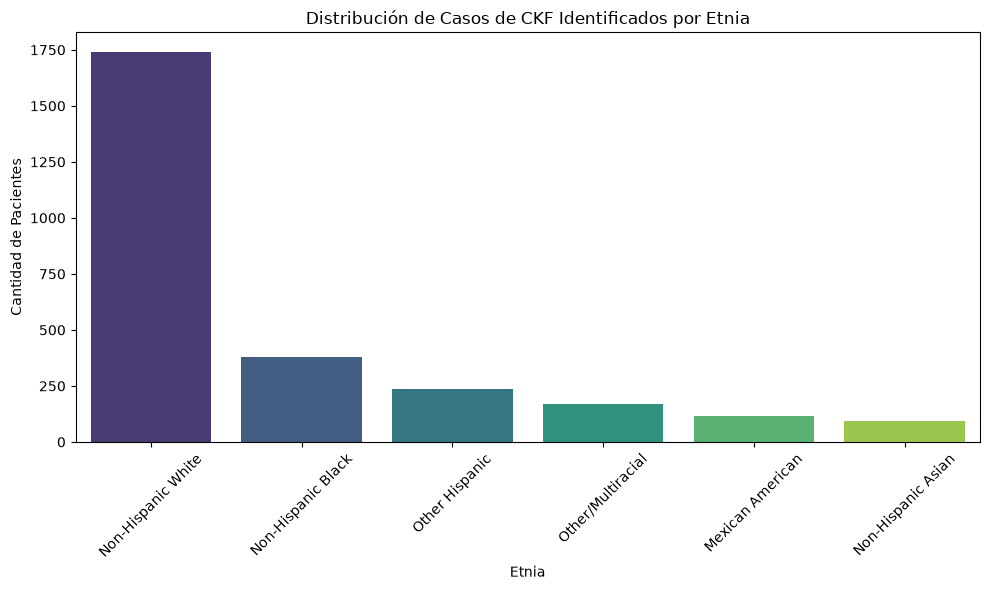

--------------------------------------------------
Casos observados por etnia:
ethnicity
Non-Hispanic White    1741
Non-Hispanic Black     377
Other Hispanic         235
Other/Multiracial      169
Mexican American       118
Non-Hispanic Asian      94
Name: count, dtype: int64
--------------------------------------------------
Test Chi-cuadrado: Estadístico = 4463.709, p-valor = 0.0000e+00
-> Se rechaza H0: Existen diferencias significativas en la cantidad de casos por etnia.



In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

filas_identificadas = (data['ckd_present'] == 1) & (data['ckd_stage'].notna())

data_h1Profes = data[filas_identificadas].copy()

conteo_etnias = data_h1Profes['ethnicity'].value_counts()
print("=== CASOS DE CKF IDENTIFICADOS POR ETNIA ===")
print(conteo_etnias)

#Graficar para el análisis exploratorio
if not conteo_etnias.empty:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=conteo_etnias.index, 
        y=conteo_etnias.values, 
        palette='viridis', 
        hue=conteo_etnias.index, 
        legend=False
    )
    plt.title('Distribución de Casos de CKF Identificados por Etnia')
    plt.xlabel('Etnia')
    plt.ylabel('Cantidad de Pacientes')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame filtrado está vacío, no hay datos para graficar.")

print("-" * 50)

#Test de Chi-cuadrado
conteo = data_h1Profes['ethnicity'].value_counts()
print("Casos observados por etnia:")
print(conteo)
print("-" * 50)

alpha = 0.05  # Nivel de significancia

chi2, p_valor = stats.chisquare(f_obs=conteo)

print(f"Test Chi-cuadrado: Estadístico = {chi2:.3f}, p-valor = {p_valor:.4e}")

if p_valor < alpha:
    print("-> Se rechaza H0: Existen diferencias significativas en la cantidad de casos por etnia.\n")
else:
    print("-> No se rechaza H0.\n")